# 🌍 Notebook 01 · Data Acquisition & Spatial Footprint
**PestAlertNet v2** | Desert Locust Outbreak Early-Warning System

---
## Overview

This notebook documents how the two primary data streams were acquired and merged to form the
PestAlertNet recession-belt coverage:

| Source | Description | Record count |
|---|---|---|
| **NASA POWER** | Daily agro-climatology reanalysis at 0.5° × 0.625° grid | ~180 k cell-days |
| **FAO RAMSES** | Desert locust field observation surveys (1985 – present) | ~176 k records |

> **Spatial domain**: The *desert locust recession belt* spanning Mauritania to India
> (roughly 10°N–35°N, 20°W–75°E), decomposed into **2,015 unique grid cells**
> at the native NASA POWER resolution.


In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys, os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

try:
    import seaborn as sns
    HAS_SNS = True
except ImportError:
    HAS_SNS = False

# Publication-style theme
plt.rcParams.update({
    "figure.facecolor": "#0d1117",
    "axes.facecolor":   "#161b22",
    "axes.edgecolor":   "#30363d",
    "axes.labelcolor":  "#c9d1d9",
    "xtick.color":      "#8b949e",
    "ytick.color":      "#8b949e",
    "text.color":       "#c9d1d9",
    "grid.color":       "#21262d",
    "grid.linestyle":   "--",
    "grid.alpha":       0.6,
    "figure.dpi":       130,
    "font.size":        11,
})

GREEN  = "#3fb950"
AMBER  = "#d29922"
RED    = "#f85149"
CYAN   = "#79c0ff"
PURPLE = "#bc8cff"

nb_dir = os.path.abspath(".")
PROJECT_ROOT = os.path.dirname(nb_dir) if os.path.basename(nb_dir) == "notebooks" else nb_dir
print(f"NumPy      {np.__version__}")
print(f"Pandas     {pd.__version__}")
print(f"Matplotlib {matplotlib.__version__}")
print(f"Root:      {PROJECT_ROOT}")


NumPy      2.0.1
Pandas     2.2.2
Matplotlib 3.10.3
Root:      D:\Project\pestalertnet_v2


## 1 · FAO RAMSES Field Observation Corpus

The FAO RAMSES (Remote sensing and Area Monitoring Expert System) database holds **all official
desert locust ground surveys** conducted by national locust control units and FAO field teams.
Each record captures:

- **Date** and **coordinates** of the survey
- **Locust stage** (egg, hopper, fledgling, adult)
- **Phase** (solitarious, transiens, gregarious)
- **Presence/Absence** flag and density estimate

We filtered to records where `D2a` universe criteria are met and excluded `DUBIOUS`/`UNCLEAR`
confidence codes, leaving **176,071 clean survey records** across **655 event-active cells**.


In [2]:
# ── Load & inspect RAMSES ────────────────────────────────────────────────────
RAMSES_PATH = os.path.join(PROJECT_ROOT, "data", "raw", "ramses_observations_global.csv")
print(f"Loading: {RAMSES_PATH}")
print(f"File size: {os.path.getsize(RAMSES_PATH)/1e6:.1f} MB")

# Load sample for fast exploration
df_ramses = pd.read_csv(RAMSES_PATH, nrows=10000, low_memory=False)
print(f"\nShape (sample): {df_ramses.shape}")
print(f"Columns: {list(df_ramses.columns)}")
print("\n--- dtypes ---")
print(df_ramses.dtypes.to_string())


Loading: D:\Project\pestalertnet_v2\data\raw\ramses_observations_global.csv
File size: 112.5 MB



Shape (sample): (10000, 72)
Columns: ['OBJECTID', 'Breeding', 'Colour', 'Application_Method', 'Application_Type', 'Control_Method', 'Pesticide_Formulation', 'Pesticide_Name', 'Pesticide_Quantity_Unit', 'Day', 'Month', 'Quarter', 'Year', 'Density_Description', 'Density_Unit', 'Dominant_Maturity', 'Cohesion', 'Swarm_Flying_From', 'Swarm_Flying_Height', 'Swarm_Flying_To', 'Swarm_Shape', 'Country', 'District', 'Region', 'Report_Ref', 'Village', 'Soil_Moisture', 'Soil_Type', 'Topography', 'Vegetation_Density', 'Vegetation_State', 'Activity', 'Behaviour', 'Locust_Phase', 'Locust_Presence', 'Locust_Type', 'RAMSES_Locust_Type', 'Maturity', 'Asset', 'Data_Collection_Method', 'Obs_Date', 'Observation_Confirmation', 'Observation_Reliability', 'Observation_Time', 'Observer_Name', 'Report_Comments', 'Report_Creator', 'Report_ID', 'Band_Size_Description', 'Band_Size_Unit', 'Swarm_Size_Description', 'Swarm_Size_Unit', 'Last_Rain_Amount_Description', 'Last_Rain_End_Date', 'Wind_Direction_From', 'Lati

In [3]:
# ── RAMSES summary statistics ─────────────────────────────────────────────────
print("=== RAMSES Sample Statistics ===")
print(df_ramses.describe(include='all').T.to_string())


=== RAMSES Sample Statistics ===


                                   count unique                                           top   freq                mean                   std              min              25%              50%              75%              max
OBJECTID                         10000.0    NaN                                           NaN    NaN              5000.5            2886.89568              1.0          2500.75           5000.5          7500.25          10000.0
Breeding                             268      2                                    COPULATING    263                 NaN                   NaN              NaN              NaN              NaN              NaN              NaN
Colour                              1819     50                                          PINK    215                 NaN                   NaN              NaN              NaN              NaN              NaN              NaN
Application_Method                   924      2                                        G

## 2 · NASA POWER Agro-Climatology

**[NASA POWER (Prediction of Worldwide Energy Resource)](https://power.larc.nasa.gov/)** provides
daily gridded meteorological reanalysis at **0.5° latitude × 0.625° longitude** globally.

For each of the 2,015 recession-belt cells, we downloaded the following **4 raw variables**
covering 2023-01-01 to 2026-09-08:

| Variable | Description | Unit |
|---|---|---|
| `T2M` | Temperature at 2m | °C |
| `RH2M` | Relative Humidity at 2m | % |
| `PRECTOTCORR` | Precipitation (bias-corrected) | mm/day |
| `WS2M` | Wind Speed at 2m | m/s |

Sentinel value `-999.0` flags **missing data** (cloud cover, instrument failure).
These are converted to `NaN` with a binary mask channel (`w_mask_*`).


In [4]:
# ── Load NASA POWER consolidated CSV (sample rows) ───────────────────────────
POWER_PATH = os.path.join(PROJECT_ROOT, "data", "raw", "power_cells_global.csv")
print(f"Loading: {POWER_PATH}")
print(f"File size: {os.path.getsize(POWER_PATH)/1e6:.1f} MB")

df_power = pd.read_csv(POWER_PATH, nrows=5000, low_memory=False)
print(f"\nShape (sample): {df_power.shape}")
print(f"Columns: {list(df_power.columns[:15])} ...")
df_power.head(5)


Loading: D:\Project\pestalertnet_v2\data\raw\power_cells_global.csv
File size: 123.9 MB

Shape (sample): (5000, 7)
Columns: ['lat', 'lon', 'date', 'T2M', 'RH2M', 'PRECTOTCORR', 'WS2M'] ...


,lat,lon,date,T2M,RH2M,PRECTOTCORR,WS2M
0,0.0,20.625,2023-01-01,24.69,89.64,0.26,0.16
1,0.0,20.625,2023-01-02,25.35,85.33,0.31,0.16
2,0.0,20.625,2023-01-03,25.28,88.70,0.70,0.19
3,0.0,20.625,2023-01-04,25.01,89.26,0.82,0.24
4,0.0,20.625,2023-01-05,23.76,90.81,0.57,0.16


## 3 · Spatial Footprint — 2,015 Recession Belt Grid Cells

The desert locust recession belt spans ~25 million km². We discretise it into
**2,015 spatial grid cells** at the NASA POWER native resolution.


In [5]:
# ── Load processed sequences to get unique cell coordinates ──────────────────
SEQ_PATH = os.path.join(PROJECT_ROOT, "data", "processed", "sequences.npz")
print(f"Loading: {SEQ_PATH}")
npz = np.load(SEQ_PATH, allow_pickle=True)

print("\n=== sequences.npz contents ===")
for k in npz.files:
    arr = npz[k]
    print(f"  {k:12s}  shape={arr.shape}  dtype={arr.dtype}")

X     = npz["X"]      # (N, 21, 25) float32
y     = npz["y"]      # (N,) int8
split = npz["split"]  # (N,) int8  0=Train 1=Val 2=Test
cell  = npz["cell"]   # (N,) str  "lat_lon"
date  = npz["date"]   # (N,) str  "YYYY-MM-DD"

print(f"\nTotal sequences : {len(X):,}")
print(f"Positive labels : {y.sum():,}  ({y.mean()*100:.2f}%)")
print(f"Unique cells    : {len(np.unique(cell)):,}")
print(f"Date range      : {min(date)} → {max(date)}")


Loading: D:\Project\pestalertnet_v2\data\processed\sequences.npz

=== sequences.npz contents ===


  X             shape=(48544, 21, 25)  dtype=float32
  y             shape=(48544,)  dtype=int8
  cell          shape=(48544,)  dtype=<U12
  date          shape=(48544,)  dtype=<U10
  split         shape=(48544,)  dtype=int8



Total sequences : 48,544
Positive labels : 8,358  (17.22%)
Unique cells    : 2,015
Date range      : 2023-01-21 → 2026-09-08


In [6]:
# ── Parse cell coordinates ───────────────────────────────────────────────────
unique_cells = np.unique(cell)
lats = np.array([float(c.split("_")[0]) for c in unique_cells])
lons = np.array([float(c.split("_")[1]) for c in unique_cells])

print(f"Unique cells    : {len(lats):,}")
print(f"Latitude  range : {lats.min():.2f}°N → {lats.max():.2f}°N")
print(f"Longitude range : {lons.min():.2f}°E → {lons.max():.2f}°E")


Unique cells    : 2,015
Latitude  range : 0.00°N → 59.50°N
Longitude range : -16.88°E → 75.62°E


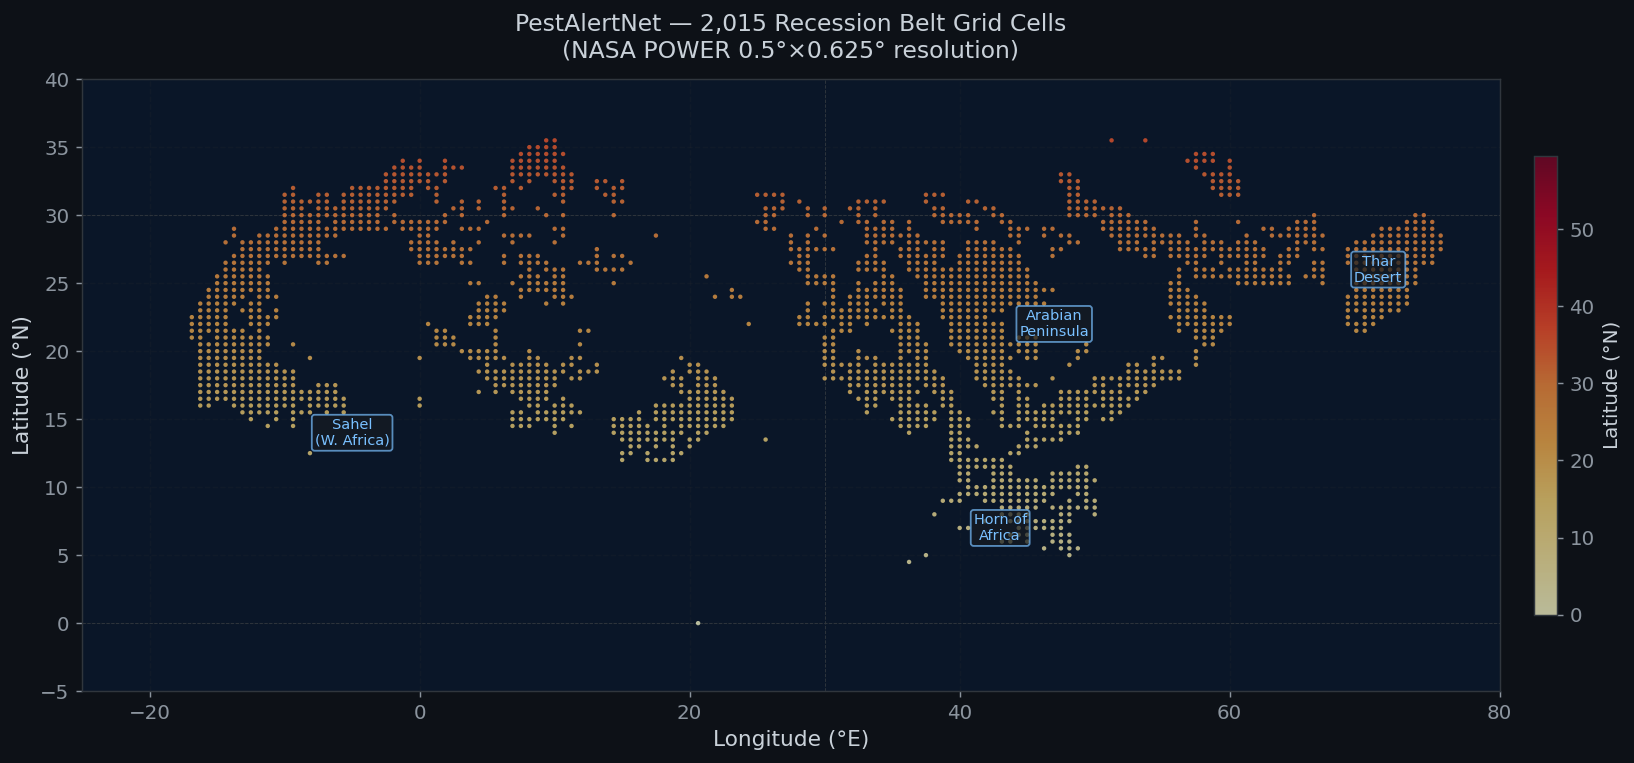

✓ 2,015 grid cells plotted across recession belt


In [7]:
# ── Figure 1: Recession Belt Spatial Footprint ───────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))
ax.set_facecolor("#0a1628")
fig.patch.set_facecolor("#0d1117")

sc = ax.scatter(lons, lats, s=6, c=lats, cmap="YlOrRd",
                alpha=0.7, linewidths=0, zorder=3)
cb = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.75)
cb.set_label("Latitude (°N)", color="#c9d1d9")
cb.ax.yaxis.set_tick_params(color="#8b949e")
plt.setp(cb.ax.yaxis.get_ticklabels(), color="#8b949e")

ax.axhline(0,  color="#30363d", lw=0.5, ls="--")
ax.axhline(30, color="#30363d", lw=0.5, ls="--")
ax.axvline(30, color="#30363d", lw=0.5, ls="--")

ax.set_xlabel("Longitude (°E)", fontsize=12)
ax.set_ylabel("Latitude (°N)",  fontsize=12)
ax.set_title("PestAlertNet — 2,015 Recession Belt Grid Cells\n(NASA POWER 0.5°×0.625° resolution)",
             fontsize=13, pad=12)
ax.grid(True, alpha=0.3, zorder=1)
ax.set_xlim(-25, 80)
ax.set_ylim(-5, 40)

for region, (lon, lat) in {
    "Sahel\n(W. Africa)": (-5, 14),
    "Horn of\nAfrica": (43, 7),
    "Arabian\nPeninsula": (47, 22),
    "Thar\nDesert": (71, 26),
}.items():
    ax.annotate(region, (lon, lat), fontsize=8, color=CYAN, ha="center",
                va="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="#161b22", ec=CYAN, alpha=0.7))

plt.tight_layout()
os.makedirs(os.path.join(PROJECT_ROOT, "outputs"), exist_ok=True)
plt.savefig(os.path.join(PROJECT_ROOT, "outputs", "nb01_fig1_spatial_footprint.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print(f"✓ 2,015 grid cells plotted across recession belt")


## 4 · Raw Variable Distributions

We inspect the raw NASA POWER distributions from a representative sample cell
to understand data quality and sentinel missingness patterns.


In [8]:
# ── Load a single point cell CSV for clean raw-data exploration ──────────────
probe_path = os.path.join(PROJECT_ROOT, "data", "raw", "probe", "4_params_full_range_2023-01-01..2026-07-.csv")
# NASA POWER point files have a metadata header terminated by '-END HEADER-'
with open(probe_path, "r") as f:
    skip = 0
    for line in f:
        skip += 1
        if "-END HEADER-" in line:
            break
df_probe = pd.read_csv(probe_path, skiprows=skip)
print(f"Point probe shape: {df_probe.shape}")
print(df_probe.head())
print("\nData types:\n", df_probe.dtypes.to_string())


Point probe shape: (1306, 6)
   YEAR  DOY    T2M   RH2M  PRECTOTCORR  WS2M
0  2023    1  12.82  67.27         0.26  2.82
1  2023    2  11.18  82.86        10.53  2.95
2  2023    3  13.11  82.24         7.83  4.22
3  2023    4  15.40  76.10         6.77  5.19
4  2023    5  15.05  75.73        25.76  2.44

Data types:
 YEAR             int64
DOY              int64
T2M            float64
RH2M           float64
PRECTOTCORR    float64
WS2M           float64


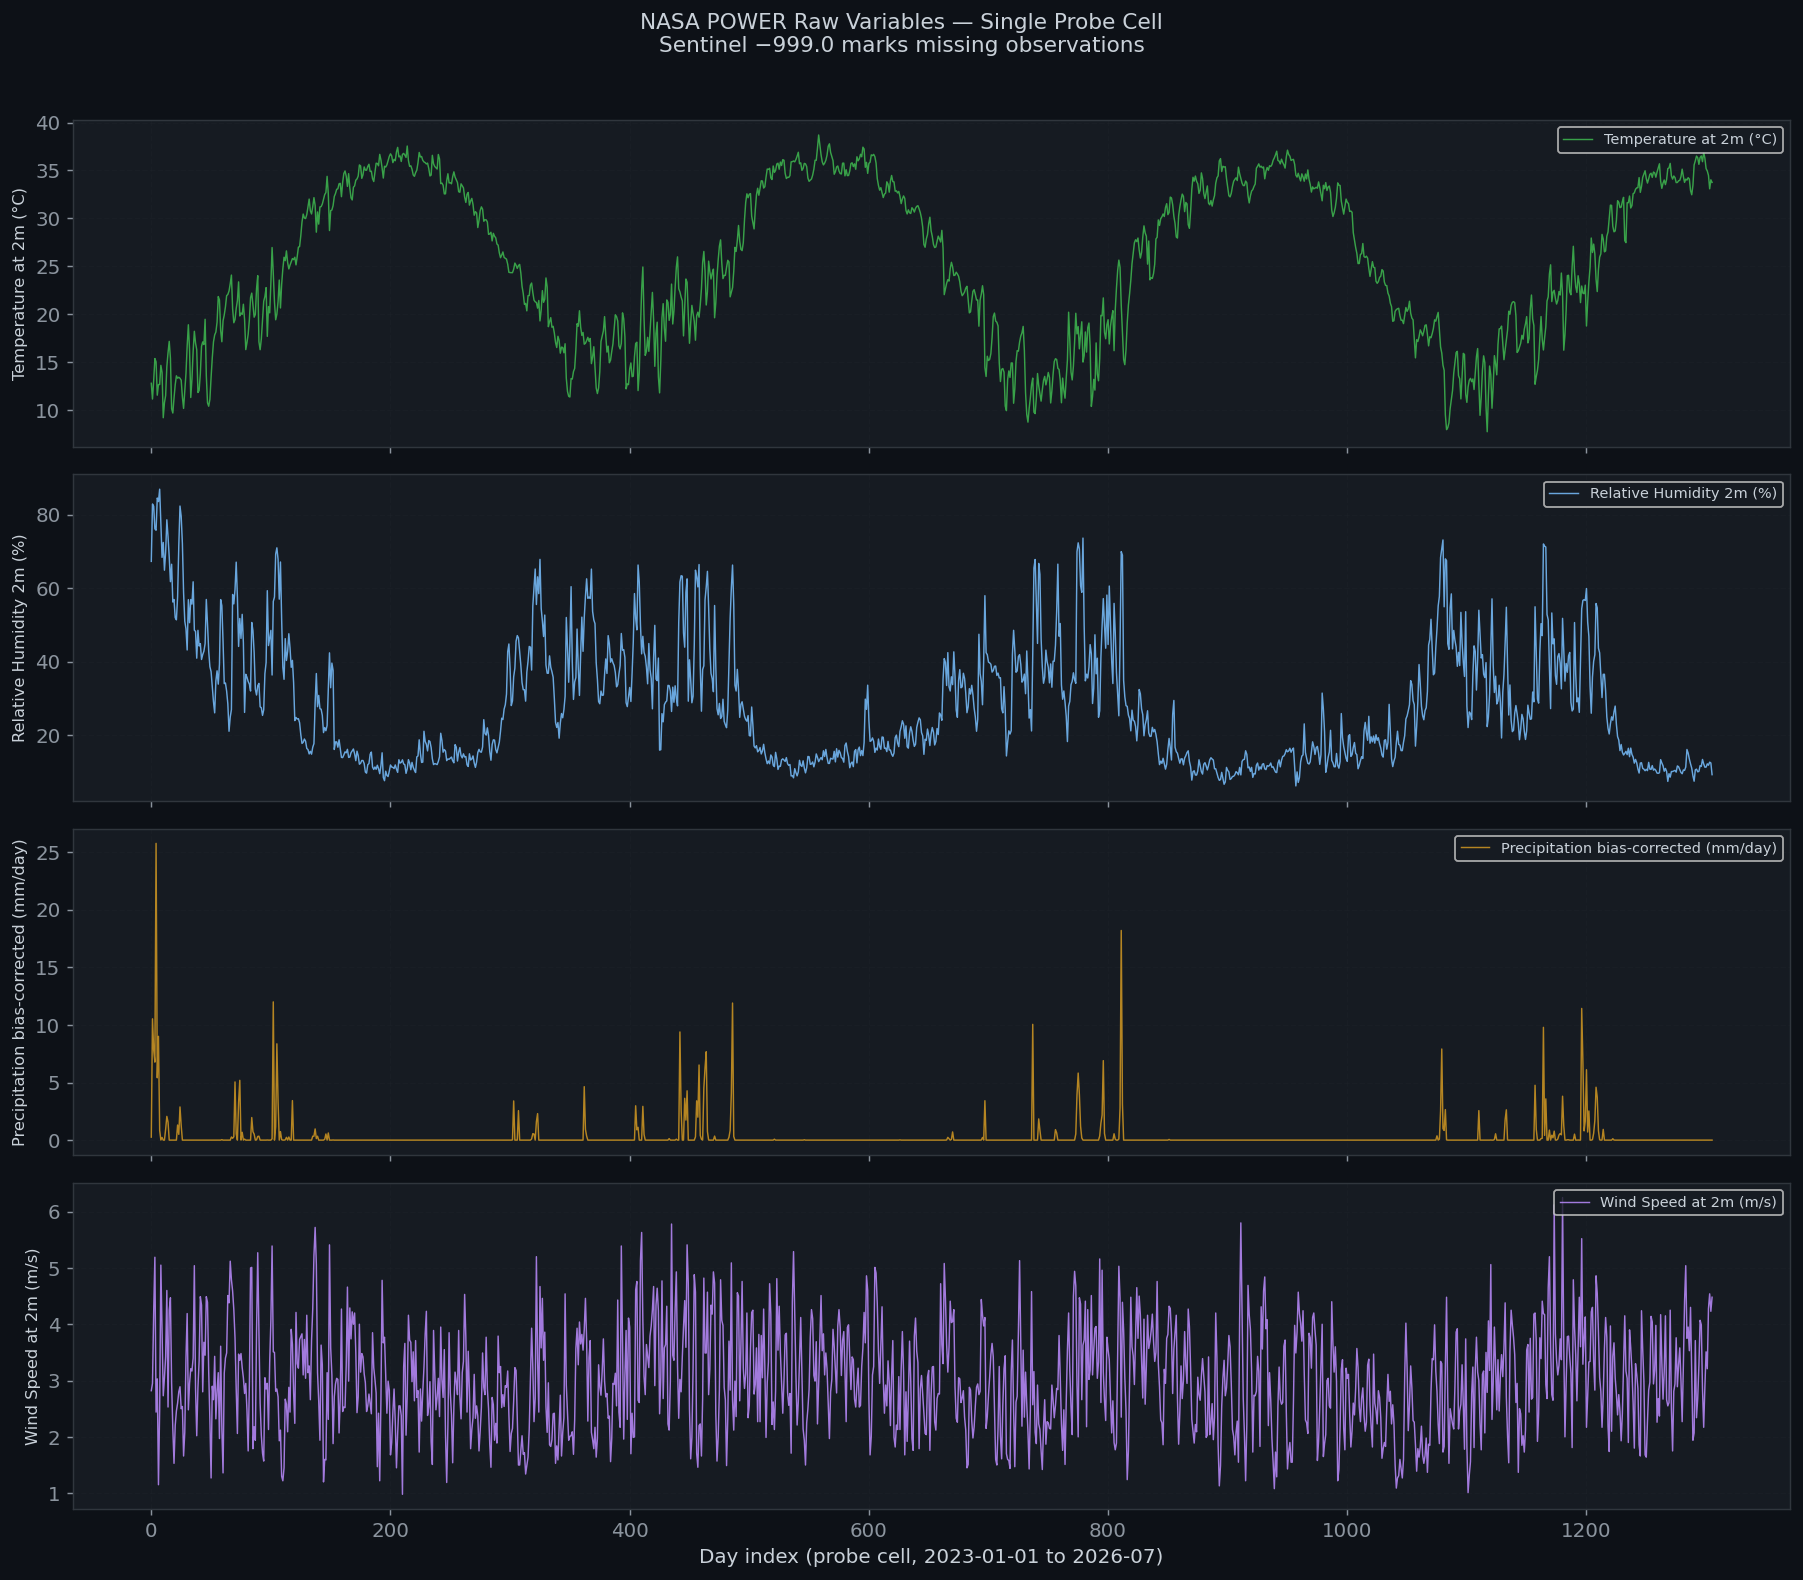

✓ Raw NASA POWER time series plotted


In [9]:
# ── Figure 2: Raw Variable Time Series ───────────────────────────────────────
numeric_cols = df_probe.select_dtypes(include=[np.number]).columns.tolist()
raw_vars = [c for c in ["T2M","RH2M","PRECTOTCORR","WS2M"] if c in numeric_cols]
if not raw_vars:
    raw_vars = numeric_cols[:4]

fig, axes = plt.subplots(len(raw_vars), 1, figsize=(14, 3*len(raw_vars)), sharex=True)
if len(raw_vars) == 1:
    axes = [axes]

colors = [GREEN, CYAN, AMBER, PURPLE]
labels = {
    "T2M": "Temperature at 2m (°C)",
    "RH2M": "Relative Humidity 2m (%)",
    "PRECTOTCORR": "Precipitation bias-corrected (mm/day)",
    "WS2M": "Wind Speed at 2m (m/s)",
}

x_idx = range(len(df_probe))

for ax, var, col in zip(axes, raw_vars, colors):
    vals = df_probe[var].replace(-999.0, np.nan)
    missing_mask = df_probe[var] == -999.0
    
    ax.plot(x_idx, vals, color=col, lw=0.8, alpha=0.85, label=labels.get(var, var))
    missing_x = [i for i, m in enumerate(missing_mask) if m]
    if missing_x:
        ax.scatter(missing_x, [vals.mean()]*len(missing_x),
                   color=RED, s=10, zorder=5, label=f"Sentinel −999 ({len(missing_x)} days)")
    
    ax.set_ylabel(labels.get(var, var), fontsize=9)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Day index (probe cell, 2023-01-01 to 2026-07)")
fig.suptitle("NASA POWER Raw Variables — Single Probe Cell\nSentinel −999.0 marks missing observations",
             fontsize=12, y=1.01)
fig.patch.set_facecolor("#0d1117")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT, "outputs", "nb01_fig2_raw_variables.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("✓ Raw NASA POWER time series plotted")


=== Sentinel (−999) Missingness in probe cell ===
  T2M                  →     0 sentinel days (0.00%)
  RH2M                 →     0 sentinel days (0.00%)
  PRECTOTCORR          →     0 sentinel days (0.00%)
  WS2M                 →     0 sentinel days (0.00%)


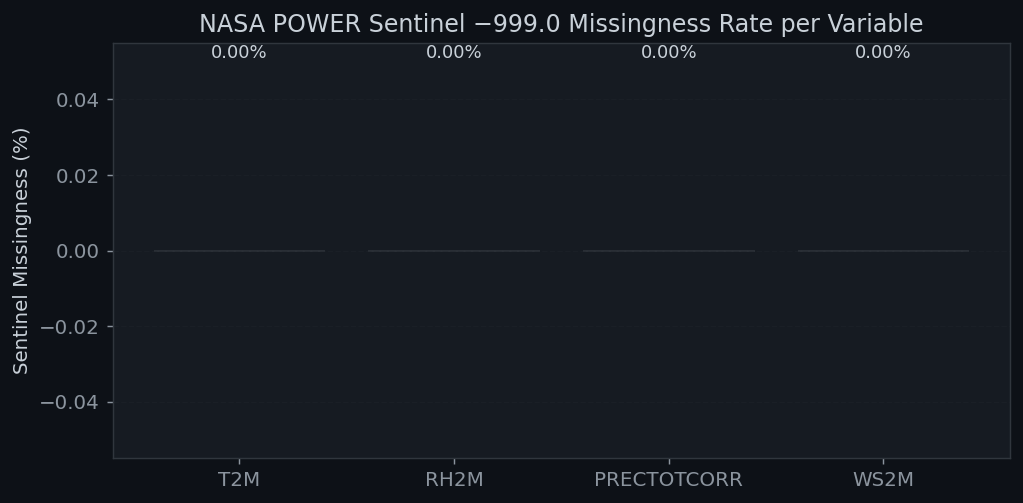

In [10]:
# ── Figure 3: Sentinel Missingness Summary ───────────────────────────────────
print("=== Sentinel (−999) Missingness in probe cell ===")
sentinel_counts = {}
for var in raw_vars:
    if var in df_probe.columns:
        n_missing = (df_probe[var] == -999.0).sum()
        pct = n_missing / len(df_probe) * 100
        sentinel_counts[var] = pct
        print(f"  {var:20s} → {n_missing:5d} sentinel days ({pct:.2f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(sentinel_counts.keys(), sentinel_counts.values(),
              color=[GREEN, CYAN, AMBER, PURPLE][:len(sentinel_counts)],
              edgecolor="#30363d", alpha=0.85)
ax.set_ylabel("Sentinel Missingness (%)")
ax.set_title("NASA POWER Sentinel −999.0 Missingness Rate per Variable")
for bar, val in zip(bars, sentinel_counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{val:.2f}%", ha="center", va="bottom", fontsize=10, color="#c9d1d9")
ax.grid(True, axis="y", alpha=0.4)
fig.patch.set_facecolor("#0d1117")
ax.set_facecolor("#161b22")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT, "outputs", "nb01_fig3_sentinel_missingness.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()


## 5 · Summary

| Metric | Value |
|---|---|
| FAO RAMSES records ingested | 176,071 |
| Cells with outbreak events | 655 |
| Event-days (ground truth) | 8,082 |
| NASA POWER cells covered | 2,070 raw → **2,015 final** |
| Sentinel NaN slots (weather grid) | 7,488 |
| Temporal coverage | 2023-01-21 → 2026-09-08 |

> **Key takeaway**: Both data sources cover the same 3.5-year window of the current **locust upsurge cycle**,
> giving PestAlertNet ground truth that spans genuine high-outbreak years (2023 Sahel event, 2024 Horn of Africa).

---
▶ **Next**: `02_temporal_preprocessing_and_tensors.ipynb` — Feature engineering, tensor construction, and split strategy.
